# Task 5: Machine Learning Classification Model (Netflix Dataset)

**Goal:** build a machine learning model that classifies Netflix content based on its available features, and compare several algorithms.

**Workflow**
1. Select and prepare features
2. Split data into training and testing sets
3. Train classification models
4. Evaluate model performance
5. Compare model accuracy

**Input:** `netflix_cleaned.csv` from Task 1.

## Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "figure.dpi": 110,
})

df = pd.read_csv("netflix_cleaned.csv")
print("Titles:", len(df))

Titles: 8786


## Step 1: Select and prepare features

### Choosing what to classify

The obvious target is **Movie vs TV Show**. Before using it, check whether it is a meaningful problem or whether the answer is already hidden in the features.

In [2]:
genre_lists = df["listed_in"].str.split(", ")
mlb_check = MultiLabelBinarizer()
G_all = pd.DataFrame(mlb_check.fit_transform(genre_lists), columns=mlb_check.classes_)

# Is every genre tag used by only one type?
tag_types = G_all.groupby(df["type"]).sum().T
mixed_tags = tag_types[(tag_types["Movie"] > 0) & (tag_types["TV Show"] > 0)]
print("Genre tags:", len(tag_types))
print("Tags used by BOTH movies and TV shows:", len(mixed_tags))
tag_types.head(8)

Genre tags: 42
Tags used by BOTH movies and TV shows: 0


type,Movie,TV Show
Action & Adventure,859,0
Anime Features,71,0
Anime Series,0,174
British TV Shows,0,252
Children & Family Movies,641,0
Classic & Cult TV,0,26
Classic Movies,116,0
Comedies,1673,0


In [3]:
# A model trained on genres alone
y_type = df["type"]
X_tr, X_te, y_tr, y_te = train_test_split(G_all, y_type, test_size=0.2, stratify=y_type, random_state=RANDOM_STATE)
leak_model = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
print("Movie vs TV accuracy from genre tags alone:", accuracy_score(y_te, leak_model.predict(X_te)))

Movie vs TV accuracy from genre tags alone: 1.0


**This is target leakage.** Netflix uses separate genre tags for films and series ("Dramas" vs "TV Dramas"), so every tag belongs to only one type, and a model gets 100% accuracy just by reading the tag. The `duration` column leaks it too (minutes vs seasons). A 100% model here would prove nothing.

### The chosen target: audience rating

Instead, the model predicts **who the content is for**: Kids, Teens or Adults, grouped from the official rating (see Task 1).

This is a realistic business problem: when new content is added, a model like this could suggest a likely maturity level for review, or flag titles whose rating looks inconsistent with their genre. It is also genuinely hard, because a genre like "Comedies" or "Dramas" spans all age groups.

- `Little Kids` and `Older Kids` are merged into **Kids** (the line between them is fine-grained and depends on content details not in the data).
- `Unrated` titles (about 1%) are removed, since they have no label to learn.

In [4]:
data = df[df["audience"] != "Unrated"].copy()
data["target"] = data["audience"].replace({"Little Kids": "Kids", "Older Kids": "Kids"})
CLASSES = ["Kids", "Teens", "Adults"]

counts = data["target"].value_counts().reindex(CLASSES)
pd.DataFrame({"titles": counts, "percent": (counts / len(data) * 100).round(1)})

,titles,percent
target,,
Kids,2054,23.6
Teens,2645,30.4
Adults,4005,46.0


The classes are moderately imbalanced (Adults is the largest at 46%). Because of that, accuracy alone can be misleading, so models are also judged on **macro F1**, which weights the three classes equally.

### Features

| Feature | How it is encoded | Why |
|---|---|---|
| Genres (`listed_in`) | One column per genre tag (1 = has tag) | Strongest content signal; a title can have several |
| Country | One-hot for the 15 most common countries in training data, rest = Other | Rating norms and content vary by market |
| Type | 1 = TV Show | Allowed as an input here; it is not the target |
| Movie minutes, TV seasons | Numbers (0 when not applicable) | Kids' content is often short |
| Release year, year added, years to Netflix | Numbers | Content era |
| Genre count | Number | Breadth of tagging |
| Director missing | 1 / 0 | Data quality flag from Task 1 |

Excluded: `title` and `director` names (almost all unique, so the model would memorize rather than learn) and `rating` (it *is* the answer).

## Step 2: Split into training and testing sets

The split happens **before** any encoding is fitted, so information from the test set cannot leak into training (for example, the list of top countries is chosen from training data only).

- 80% training, 20% testing
- **Stratified** so each set has the same Kids/Teens/Adults mix
- Fixed random seed so results are reproducible

In [5]:
train_df, test_df = train_test_split(
    data, test_size=0.2, stratify=data["target"], random_state=RANDOM_STATE
)
print("Train:", len(train_df), "| Test:", len(test_df))
pd.DataFrame({
    "train %": train_df["target"].value_counts(normalize=True).reindex(CLASSES).mul(100).round(1),
    "test %": test_df["target"].value_counts(normalize=True).reindex(CLASSES).mul(100).round(1),
})

Train: 6963 | Test: 1741


,train %,test %
target,,
Kids,23.6,23.6
Teens,30.4,30.4
Adults,46.0,46.0


In [6]:
# Fit the encoders on training data only
mlb = MultiLabelBinarizer().fit(train_df["listed_in"].str.split(", "))
top_countries = train_df.loc[train_df["country"] != "Unknown", "country"].value_counts().head(15).index

def build_features(part):
    genres = pd.DataFrame(
        mlb.transform(part["listed_in"].str.split(", ")),
        columns=["genre_" + g for g in mlb.classes_], index=part.index,
    )
    country = part["country"].where(part["country"].isin(top_countries), "Other")
    country = pd.get_dummies(country, prefix="country").astype(int)
    country = country.reindex(columns=["country_" + c for c in top_countries] + ["country_Other"], fill_value=0)
    numeric = pd.DataFrame({
        "is_tv_show": (part["type"] == "TV Show").astype(int),
        "movie_minutes": part["movie_minutes"].fillna(0),
        "tv_seasons": part["tv_seasons"].fillna(0),
        "release_year": part["release_year"],
        "year_added": part["year_added"],
        "years_to_netflix": part["years_to_netflix"],
        "genre_count": part["genre_count"],
        "director_missing": part["director_missing"].astype(int),
    }, index=part.index)
    return pd.concat([genres, country, numeric], axis=1)

X_train, X_test = build_features(train_df), build_features(test_df)
y_train, y_test = train_df["target"], test_df["target"]
print("Feature matrix:", X_train.shape, "| Same columns in test:", list(X_train.columns) == list(X_test.columns))

Feature matrix: (6963, 66) | Same columns in test: True


## Step 3: Train classification models

Five models, from simplest to most complex:

| Model | Why it is included |
|---|---|
| Baseline (most frequent) | Always predicts "Adults". Any useful model must beat this. |
| Logistic Regression | Simple, interpretable linear model. Features are scaled first. |
| Decision Tree | Learns readable if/then rules; prone to overfitting. |
| Random Forest | Many trees averaged together; reduces overfitting. |
| Gradient Boosting | Trees built in sequence, each fixing the last one's errors; often the strongest on tabular data. |

`class_weight="balanced"` is used where available so the models do not ignore the smaller Kids class.

Each model is compared with **5-fold cross-validation on the training set only**. The test set is kept untouched until the final evaluation.

In [7]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["accuracy", "f1_macro"], return_train_score=True)
    cv_rows[name] = {
        "CV accuracy": res["test_accuracy"].mean(),
        "CV accuracy (std)": res["test_accuracy"].std(),
        "CV macro F1": res["test_f1_macro"].mean(),
        "Train accuracy": res["train_accuracy"].mean(),
    }
    print(f"{name:26s} accuracy {cv_rows[name]['CV accuracy']:.3f}  macro F1 {cv_rows[name]['CV macro F1']:.3f}")

cv_results = pd.DataFrame(cv_rows).T.round(3)
cv_results["Overfit gap"] = (cv_results["Train accuracy"] - cv_results["CV accuracy"]).round(3)
cv_results

Baseline (most frequent)   accuracy 0.460  macro F1 0.210


Logistic Regression        accuracy 0.650  macro F1 0.650


Decision Tree              accuracy 0.612  macro F1 0.610


Random Forest              accuracy 0.671  macro F1 0.670


Gradient Boosting          accuracy 0.660  macro F1 0.657


,CV accuracy,CV accuracy (std),CV macro F1,Train accuracy,Overfit gap
Baseline (most frequent),0.460,0.000,0.210,0.460,0.000
Logistic Regression,0.650,0.012,0.650,0.662,0.012
Decision Tree,0.612,0.022,0.610,0.655,0.043
Random Forest,0.671,0.012,0.670,0.846,0.175
Gradient Boosting,0.660,0.011,0.657,0.836,0.176


**Reading the cross-validation results**
- Every real model clearly beats the baseline (46% accuracy, and a macro F1 near 0.21 because it never predicts Kids or Teens).
- The tree ensembles (Random Forest and Gradient Boosting) lead, but only by 1 to 2 points over Logistic Regression. Most of the signal is simple ("has a kids' genre tag"), which a linear model can capture too.
- The single Decision Tree is the weakest real model, as expected: one tree is unstable.
- The **overfit gap** (training accuracy minus CV accuracy) is about 17 points for both ensembles: they fit the training data much better than new data. Their CV scores are still the best, so this is acceptable, but it is worth tuning.
- The CV standard deviation is about 1 point, so differences smaller than that between models are not meaningful.

### Tuning the two best models

A small grid search, again using only the training set with 5-fold CV and macro F1 as the score. The grids are kept small so the notebook runs in a couple of minutes.

In [8]:
rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    {"max_depth": [None, 20], "min_samples_leaf": [1, 3], "max_features": ["sqrt", 0.3]},
    cv=cv, scoring="f1_macro", n_jobs=1,
).fit(X_train, y_train)

gb_grid = GridSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    {"learning_rate": [0.05, 0.1], "max_depth": [None, 6], "max_iter": [200, 400]},
    cv=cv, scoring="f1_macro", n_jobs=1,
).fit(X_train, y_train)

print("Random Forest best:", rf_grid.best_params_, f"CV macro F1 {rf_grid.best_score_:.3f}")
print("Gradient Boosting best:", gb_grid.best_params_, f"CV macro F1 {gb_grid.best_score_:.3f}")

Random Forest best: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3} CV macro F1 0.675
Gradient Boosting best: {'learning_rate': 0.05, 'max_depth': 6, 'max_iter': 200} CV macro F1 0.664


In [9]:
final_models = {
    "Baseline (most frequent)": models["Baseline (most frequent)"],
    "Logistic Regression": models["Logistic Regression"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest (tuned)": rf_grid.best_estimator_,
    "Gradient Boosting (tuned)": gb_grid.best_estimator_,
}
for name, m in final_models.items():
    if name not in ("Random Forest (tuned)", "Gradient Boosting (tuned)"):
        m.fit(X_train, y_train)   # grid search already refit the tuned models on all training data

## Step 4: Evaluate model performance

Now, for the first time, every model is scored on the held-out **test set**.

In [10]:
test_rows = {}
preds = {}
for name, m in final_models.items():
    p = m.predict(X_test)
    preds[name] = p
    test_rows[name] = {
        "Test accuracy": accuracy_score(y_test, p),
        "Test macro F1": f1_score(y_test, p, average="macro"),
        **{f"F1 {c}": f1_score(y_test, p, labels=[c], average="macro") for c in CLASSES},
    }
test_results = pd.DataFrame(test_rows).T.round(3)
test_results

,Test accuracy,Test macro F1,F1 Kids,F1 Teens,F1 Adults
Baseline (most frequent),0.460,0.210,0.000,0.000,0.630
Logistic Regression,0.646,0.645,0.705,0.541,0.690
Decision Tree,0.630,0.605,0.704,0.404,0.706
Random Forest (tuned),0.661,0.658,0.720,0.544,0.710
Gradient Boosting (tuned),0.664,0.661,0.720,0.547,0.714


In [11]:
best_name = test_results.drop("Baseline (most frequent)")["Test macro F1"].idxmax()
best_model = final_models[best_name]
print("Best model on test macro F1:", best_name, "\n")
print(classification_report(y_test, preds[best_name], labels=CLASSES, digits=3))

Best model on test macro F1: Gradient Boosting (tuned) 

              precision    recall  f1-score   support

        Kids      0.736     0.706     0.720       411
       Teens      0.538     0.556     0.547       529
      Adults      0.714     0.714     0.714       801

    accuracy                          0.664      1741
   macro avg      0.663     0.658     0.661      1741
weighted avg      0.666     0.664     0.665      1741



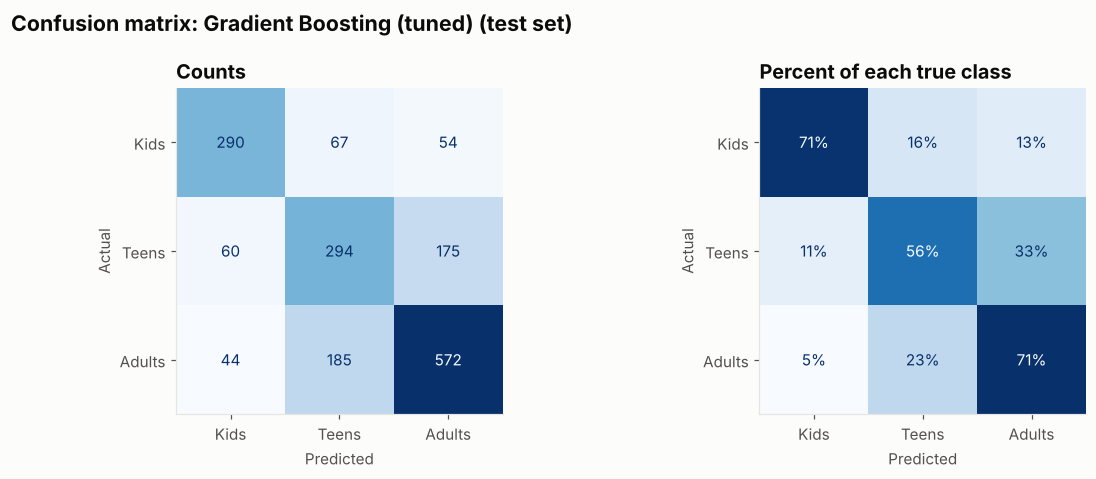

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
cm = confusion_matrix(y_test, preds[best_name], labels=CLASSES)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

for ax, values, fmt, title in [(axes[0], cm, "d", "Counts"),
                               (axes[1], cm_pct, ".0f", "Percent of each true class")]:
    disp = ConfusionMatrixDisplay(values, display_labels=CLASSES)
    disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False, values_format=fmt)
    ax.set_title(title, loc="left")
    ax.grid(False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for t in axes[1].texts:
    t.set_text(t.get_text() + "%")
fig.suptitle(f"Confusion matrix: {best_name} (test set)", x=0.01, ha="left",
             fontweight="bold", fontsize=14, color=INK)
fig.tight_layout()
fig.savefig("02_confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

**Reading the confusion matrix**
- The diagonal shows correct predictions. **Kids and Adults** are recognized best (about 71% each). Kids' content has very distinctive genre tags (Children & Family Movies, Kids' TV).
- **Teens is the hardest class** (56%), and a third of teen titles are predicted as Adults. That makes sense: PG-13/TV-14 and R/TV-MA titles share the same genres (Dramas, Action, Comedies), and what separates them (violence, language, sexual content) is not in this data.
- The most serious mistake in practice is calling adult content "Kids". That happens for only 5% of adult titles. The reverse (13% of kids' titles predicted as Adults) is less harmful but shows the model is cautious with kids' content that lacks a children's genre tag, such as family comedies.

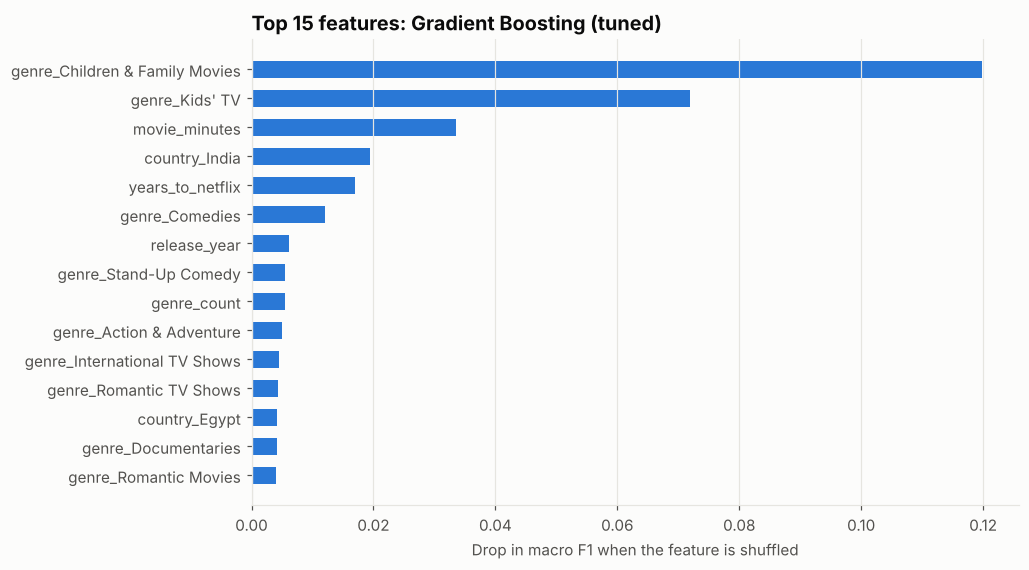

,importance
genre_Children & Family Movies,0.1198
genre_Kids' TV,0.0719
movie_minutes,0.0335
country_India,0.0194
years_to_netflix,0.0170
genre_Comedies,0.0121
release_year,0.0061
genre_Stand-Up Comedy,0.0055
genre_count,0.0054
genre_Action & Adventure,0.0050


In [13]:
# Which features matter? Permutation importance on the test set:
# shuffle one feature at a time and measure how much macro F1 drops.
perm = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = importance.head(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE, height=0.6)
ax.set_xlabel("Drop in macro F1 when the feature is shuffled")
ax.set_title(f"Top 15 features: {best_name}", loc="left")
ax.grid(axis="y", visible=False)
fig.savefig("03_feature_importance.png", bbox_inches="tight", dpi=150)
plt.show()
top.round(4).to_frame("importance")

**Reading the feature importance**
- Two genre tags dominate: **Children & Family Movies** and **Kids' TV**. Removing either one hurts the model far more than any other feature. The model is essentially strongest at spotting kids' content.
- **Movie length** comes next. Kids' films and specials tend to be short.
- **India** is the most important country. Indian titles are often rated TV-14 in this dataset, so country helps separate Teens from Adults.
- Time features (years to Netflix, release year) add a little: older catalog titles carry different ratings from new releases.

## Step 5: Compare model accuracy

In [14]:
comparison = pd.DataFrame({
    "CV accuracy (train)": [cv_results.loc[n.replace(" (tuned)", ""), "CV accuracy"] for n in final_models],
    "Test accuracy": test_results["Test accuracy"],
    "Test macro F1": test_results["Test macro F1"],
}, index=list(final_models)).round(3)
comparison

,CV accuracy (train),Test accuracy,Test macro F1
Baseline (most frequent),0.460,0.460,0.210
Logistic Regression,0.650,0.646,0.645
Decision Tree,0.612,0.630,0.605
Random Forest (tuned),0.671,0.661,0.658
Gradient Boosting (tuned),0.660,0.664,0.661


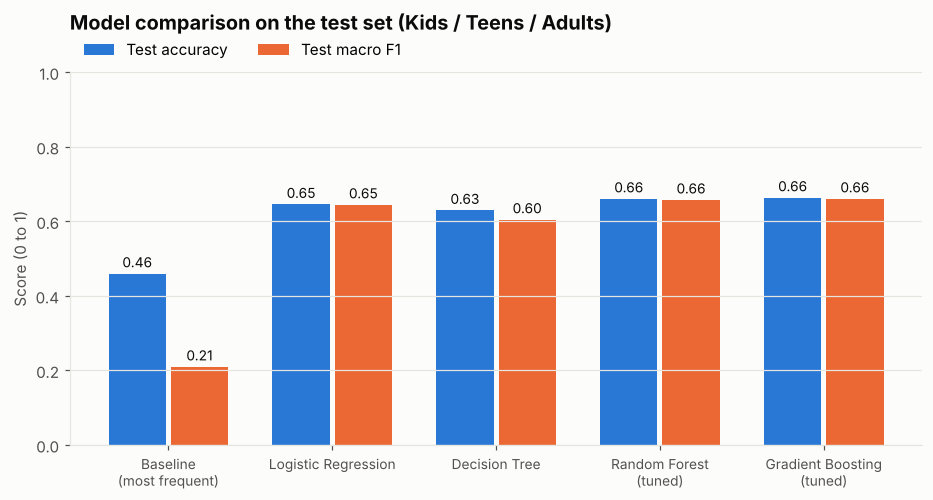

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.4))
names = comparison.index
x = np.arange(len(names)); w = 0.38
b1 = ax.bar(x - w / 2, comparison["Test accuracy"], w - 0.03, color=BLUE, label="Test accuracy")
b2 = ax.bar(x + w / 2, comparison["Test macro F1"], w - 0.03, color=ORANGE, label="Test macro F1")
ax.bar_label(b1, fmt="%.2f", fontsize=9, color=INK, padding=2)
ax.bar_label(b2, fmt="%.2f", fontsize=9, color=INK, padding=2)
ax.set_xticks(x, [n.replace(" (", "\n(") for n in names], fontsize=9)
ax.set_ylim(0, 1)
ax.set_ylabel("Score (0 to 1)")
ax.set_title("Model comparison on the test set (Kids / Teens / Adults)", loc="left", pad=28)
ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.grid(axis="x", visible=False)
fig.savefig("01_model_comparison.png", bbox_inches="tight", dpi=150)
plt.show()

In [16]:
# Sanity check: example predictions with the model's confidence
sample = test_df.sample(8, random_state=7)
proba = best_model.predict_proba(X_test.loc[sample.index])
out = sample[["title", "type", "listed_in", "rating", "target"]].copy()
out["predicted"] = best_model.predict(X_test.loc[sample.index])
out["confidence"] = proba.max(axis=1).round(2)
out.rename(columns={"target": "actual"}).reset_index(drop=True)

,title,type,listed_in,rating,actual,predicted,confidence
0,Red Christmas,Movie,Horror Movies,TV-MA,Adults,Adults,0.77
1,Single Wives,TV Show,"Reality TV, Romantic TV Shows",TV-MA,Adults,Teens,0.45
2,Njan Prakashan,Movie,"Comedies, Dramas, International Movies",TV-PG,Kids,Teens,0.64
3,Christmas with the Kranks,Movie,"Children & Family Movies, Comedies",PG,Kids,Kids,0.99
4,Elf Pets: A Fox Cub’s Christmas Tale,Movie,Children & Family Movies,TV-Y,Kids,Kids,1.00
5,Terrace House: Aloha State,TV Show,"International TV Shows, Reality TV",TV-14,Teens,Kids,0.45
6,Terrace House: Tokyo 2019-2020,TV Show,"International TV Shows, Reality TV",TV-MA,Adults,Kids,0.43
7,Canvas,Movie,"Children & Family Movies, Dramas",G,Kids,Kids,0.99


## Summary

**Problem framing**
- The obvious target, Movie vs TV Show, was rejected after finding **target leakage**: genre tags are type-specific, so any model scores 100% without learning anything. Spotting this is more valuable than reporting a perfect score.
- The model instead predicts the **audience rating group** (Kids, Teens, Adults) from genres, country, format and dates.

**Results** (exact numbers are in the tables above)
- All models beat the majority-class baseline by a wide margin.
- **Gradient Boosting (tuned) performed best:** 66.4% accuracy and 0.66 macro F1 on unseen titles, against 46% accuracy for always guessing "Adults". Random Forest was virtually tied, and Logistic Regression was close behind (64.6%).
- Test scores match the cross-validation scores closely, so the results should hold on new data from the same source.
- **Kids and Adults are each recognized about 71% of the time; Teens is the weak spot (56%)**, mostly confused with Adults, because teen and adult content share the same genres.
- Only 5% of adult titles were predicted as Kids, the most costly type of error.

**Limitations**
- The biggest drivers of a rating (violence, language, sexual content, themes) are not in the data. Plot descriptions or content tags would likely improve Teens vs Adults the most.
- Ratings come from two systems (TV and MPAA) and different countries' standards, which adds label noise.
- Results are from one dataset snapshot. Before any real use, the model would need checking on newer titles.

**Practical use:** this is a decision-support tool, not a replacement for human rating. A sensible use is to flag titles where the predicted audience disagrees strongly with the assigned rating, for a person to review.